In [8]:
# 01_load_and_explore.py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openml
import warnings
import os
warnings.filterwarnings('ignore')

# ============================================================
# BLOC 1 — CHARGEMENT DES DONNÉES
# ============================================================
# freMTPL2freq = dataset OpenML id 41214
# freMTPL2sev  = dataset OpenML id 41215
# Ces datasets sont les mêmes que ceux du package R CASdatasets

dataset_freq = openml.datasets.get_dataset(41214)
dataset_sev  = openml.datasets.get_dataset(41215)

# to_dataframe() retourne (X, y, categorical_indicator, attribute_names)
freq, _, _, _ = dataset_freq.get_data(dataset_format="dataframe")
sev,  _, _, _ = dataset_sev.get_data(dataset_format="dataframe")

print(f"Table fréquence : {freq.shape}")   # (678013, 12)
print(f"Table sévérité  : {sev.shape}")    # (26639, 2)



BASE = '/content/drive/MyDrive/siap'

os.makedirs(f'{BASE}/data', exist_ok=True)

freq.to_csv(f'{BASE}/data/freq_raw.csv', index=False)
sev.to_csv(f'{BASE}/data/sev_raw.csv', index=False)

print("Fichiers sauvegardés avec succès")

Table fréquence : (678013, 12)
Table sévérité  : (26639, 2)
Fichiers sauvegardés avec succès


In [4]:
# ============================================================
# BLOC 2 — PREMIÈRES VÉRIFICATIONS (réflexe d'actuaire)
# ============================================================

# On vérifie toujours ces 4 choses en premier :

# 2a. Types et valeurs manquantes
print(freq.dtypes)
print(freq.isnull().sum())

# 2b. Distribution de la variable cible fréquence
# En actuariat Non-Vie, ClaimNb suit une loi de Poisson
# La grande majorité des polices ont 0 sinistre — c'est normal
print(freq['ClaimNb'].value_counts().head(10))
# Résultat typique :
# 0 → ~649 000 polices (95.7%)
# 1 → ~26 000 polices  ( 3.8%)
# 2 → ~2 500 polices   ( 0.4%)

# 2c. L'Exposure — crucial
print(freq['Exposure'].describe())
# min: 0.002 (1 jour), max: 1.0 (année complète)
# mean: ~0.53 → portefeuille avec beaucoup de nouvelles polices

# 2d. Distribution de ClaimAmount
print(sev['ClaimAmount'].describe())
# La distribution est fortement asymétrique à droite (loi log-normale / Gamma)
# C'est normal : quelques sinistres très coûteux tirent la moyenne vers le haut

IDpol          float64
ClaimNb          uint8
Exposure       float64
Area          category
VehPower         uint8
VehAge           uint8
DrivAge          uint8
BonusMalus       uint8
VehBrand      category
VehGas          object
Density        float64
Region        category
dtype: object
IDpol         0
ClaimNb       0
Exposure      0
Area          0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Density       0
Region        0
dtype: int64
ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
11         3
5          2
6          1
8          1
16         1
Name: count, dtype: int64
count    678013.000000
mean          0.528750
std           0.364442
min           0.002732
25%           0.180000
50%           0.490000
75%           0.990000
max           2.010000
Name: Exposure, dtype: float64
count    2.663900e+04
mean     2.278536e+03
std      2.929748e+04
min      1.000000e+00
25%      6.868100e+02
50%      1.17200

In [5]:
# ============================================================
# BLOC 3 — INDICATEURS CLÉS DU PORTEFEUILLE
# (ce qu'un actuaire calcule AVANT tout modèle)
# ============================================================

# Fréquence observée du portefeuille
# = nombre total de sinistres / exposition totale
freq_portefeuille = freq['ClaimNb'].sum() / freq['Exposure'].sum()
print(f"Fréquence portefeuille : {freq_portefeuille:.4f}")
# Résultat typique : ~0.072 soit 7.2 sinistres pour 100 années-police

# Coût moyen par sinistre
cout_moyen = sev['ClaimAmount'].mean()
print(f"Coût moyen sinistre : {cout_moyen:.2f} €")
# Résultat typique : ~1 900 €

# Prime pure moyenne estimée (approximation naïve avant modélisation)
prime_pure_naive = freq_portefeuille * cout_moyen
print(f"Prime pure moyenne (estimée) : {prime_pure_naive:.2f} €")
# Résultat typique : ~137 €
# C'est le coût moyen des sinistres par police par an

Fréquence portefeuille : 0.1007
Coût moyen sinistre : 2278.54 €
Prime pure moyenne (estimée) : 229.46 €


In [6]:
# ============================================================
# BLOC 4 — ANALYSE EXPLORATOIRE PAR FACTEUR TARIFAIRE
# ============================================================

# On calcule la fréquence OBSERVÉE par tranche d'âge conducteur
# C'est ce qu'on appelle les "statistiques univariées" en tarification

freq_by_age = (
    freq.groupby(pd.cut(freq['DrivAge'], bins=[17,25,35,45,55,65,100]))
    .agg(
        nb_polices    = ('ClaimNb', 'count'),
        nb_sinistres  = ('ClaimNb', 'sum'),
        exposition    = ('Exposure', 'sum')
    )
    .assign(freq_obs = lambda d: d['nb_sinistres'] / d['exposition'])
    .reset_index()
)
print(freq_by_age)
# On voit clairement : les 18-25 ans ont une fréquence 2x plus élevée
# C'est le signal que le modèle devra capturer

# Même analyse pour BonusMalus
freq_by_bm = (
    freq.groupby(pd.cut(freq['BonusMalus'], bins=[49,80,100,120,150,231]))
    .agg(
        nb_sinistres = ('ClaimNb', 'sum'),
        exposition   = ('Exposure', 'sum')
    )
    .assign(freq_obs = lambda d: d['nb_sinistres'] / d['exposition'])
    .reset_index()
)
print(freq_by_bm)
# BonusMalus=50 (meilleurs conducteurs) → fréquence très basse
# BonusMalus>100 (malussés) → fréquence élevée
# C'est la variable la plus prédictive en RC Auto

     DrivAge  nb_polices  nb_sinistres    exposition  freq_obs
0   (17, 25]       38895          2841  16227.903263  0.175069
1   (25, 35]      149183          6662  69266.778075  0.096179
2   (35, 45]      170352          8397  87702.336287  0.095744
3   (45, 55]      161899          9256  89268.776408  0.103687
4   (55, 65]       90691          4748  51775.553261  0.091704
5  (65, 100]       66993          4198  44258.098168  0.094853
   BonusMalus  nb_sinistres     exposition  freq_obs
0    (49, 80]         29666  326283.974710  0.090921
1   (80, 100]          5094   28644.151750  0.177837
2  (100, 120]           873    2573.003003  0.339292
3  (120, 150]           415     903.187803  0.459484
4  (150, 231]            54      95.128197  0.567655


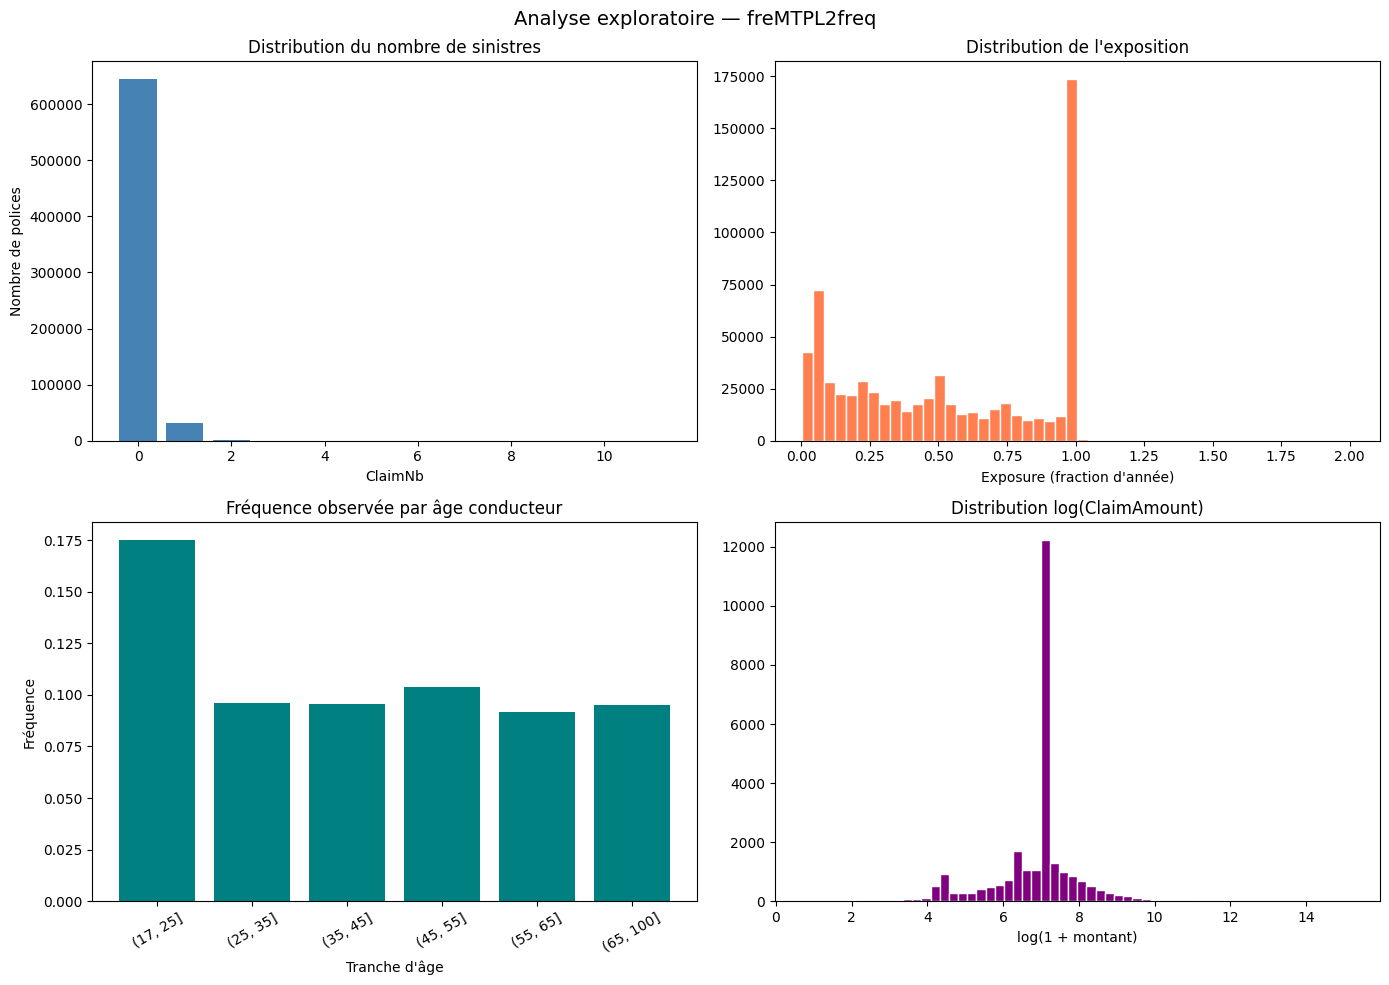

In [7]:
# ============================================================
# BLOC 5 — VISUALISATIONS ACTUARIELLES
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Analyse exploratoire — freMTPL2freq', fontsize=14)

# 5a. Distribution ClaimNb (barplot, pas histogram — variable discrète)
axes[0,0].bar(
    freq['ClaimNb'].value_counts().index[:6],
    freq['ClaimNb'].value_counts().values[:6],
    color='steelblue'
)
axes[0,0].set_title('Distribution du nombre de sinistres')
axes[0,0].set_xlabel('ClaimNb')
axes[0,0].set_ylabel('Nombre de polices')

# 5b. Distribution Exposure
axes[0,1].hist(freq['Exposure'], bins=50, color='coral', edgecolor='white')
axes[0,1].set_title("Distribution de l'exposition")
axes[0,1].set_xlabel('Exposure (fraction d\'année)')

# 5c. Fréquence par âge conducteur
ages = freq_by_age['DrivAge'].astype(str)
axes[1,0].bar(ages, freq_by_age['freq_obs'], color='teal')
axes[1,0].set_title('Fréquence observée par âge conducteur')
axes[1,0].set_xlabel('Tranche d\'âge')
axes[1,0].set_ylabel('Fréquence')
axes[1,0].tick_params(axis='x', rotation=30)

# 5d. Distribution ClaimAmount (log scale — distribution Gamma)
axes[1,1].hist(np.log1p(sev['ClaimAmount']), bins=60, color='purple', edgecolor='white')
axes[1,1].set_title('Distribution log(ClaimAmount)')
axes[1,1].set_xlabel('log(1 + montant)')

plt.tight_layout()
plt.savefig('eda_pricing.png', dpi=150, bbox_inches='tight')
plt.show()